## Dans ce notebook, on teste l'auto-encodeur sur :
1. La robustesse à la charge
2. L'influence de la normalisation des données
3. La catégorisation sain vs défaut, pour chaque type de défaut, chaque sévérité (diamètre défaut)

In [1]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features, models


I0000 00:00:1795075946.757948  169198 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
print("charges : Train sur 0, 1, 2 (charge faible), test sur 3 (charge max)")
print("Défauts : Tous type de défaut, toutes les sévérités (diamètre du défaut)")

selection = data.selectionner(
    sources=("12kDE", "Normal"),
    defauts=("IR", "B", "OR"),
    diametres=(7, 14, 21, 28), positions_or=("3", "6","12",),
    charges=(0, 1, 2, 3),
    canaux={"12kDE": ("DE",), 
            "Normal": ("DE")},
)

charges : Train sur 0, 1, 2 (charge faible), test sur 3 (charge max)
Défauts : Tous type de défaut, toutes les sévérités (diamètre du défaut)


In [3]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from Sources.data import selectionner, charger
from Sources.config import DUREE_FENETRE

print("1.Construction du tableau de données\n2.Fenêtrage avec recouvrement\n3.Normalisation")

def construire_fenetres_brutes(selection, canal="DE", duree=DUREE_FENETRE/2, recouvrement=0.5):
    """R
    envoie (SB, infos) : signaux BRUTS (pas encore normalisés) + infos par fenetre.
    Réduction de la durée de fenêtre : DUREE_FENETRE/2 = 0.1s
    100ms sufisent pour capter la fréquences des chocs s'il y'en a.
    Fenetre plus petite = entrainement moins long sans perte d'information
    Plus de fenêtre = modèle mieux entrainé
    """
    SB, lignes = [], []
    for nom, info in selection.iterrows():
        s = charger(nom, canaux=(canal))
        for i, val in enumerate(features.fenetrer(s[canal], s["fs"], duree=duree, recouvrement=recouvrement)):
            SB.append(val)                                   # brut, sans normaliser
            lignes.append({"fichier": nom, "fenetre": i, "canal": canal,
                           "defaut": info["defaut"], "charge_hp": info["charge_hp"],
                           "rpm": s["rpm"], "fs": s["fs"], 
                           "defaut_sain": "Sain" if info["defaut"] == "Sain" else "Défaut",
                           "diametre_mils": info["diametre_mils"],
                           "classe": "Sain" if info["defaut"] == "Sain" else info["defaut"] + str(info["diametre_mils"]).zfill(3)
                           })
    return np.array(SB, dtype=np.float32), pd.DataFrame(lignes)

SB, infos = construire_fenetres_brutes(selection, canal="DE")
SBNorm = StandardScaler().fit_transform(SB.T).T            # Standardisation sklearn (par colonne, D'où le .T pour convertir puis reconvertir)

tableau = pd.concat([infos.reset_index(drop=True),
                     pd.DataFrame(SBNorm, columns=[f"s{i}" for i in range(SBNorm.shape[1])])], axis=1)

1.Construction du tableau de données
2.Fenêtrage avec recouvrement
3.Normalisation


In [4]:
from sklearn.model_selection import GroupShuffleSplit

print("1.Split train/test par charge \n2.filtrage des données saines sur le train\n3.Affichage tables apprentissages\n")

def split_train_test(infos, mode="defaut", charges_train=(0, 1, 2,), charges_test=(3,)):
    """Renvoie (i_train, i_test).
    mode="defaut" : split aléatoire 75/25 par FICHIER (anti-fuite).
    mode="charge"  : train sur charges_train (HP), test sur charges_test (inter-conditions)."""
    if mode == "defaut":
        gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
        i_train, i_test = next(gss.split(infos, groups=infos["fichier"]))
    elif mode == "charge":
        i_train = np.where(infos["charge_hp"].isin(charges_train).to_numpy())[0]
        i_test  = np.where(infos["charge_hp"].isin(charges_test).to_numpy())[0]
    return i_train, i_test

mode = "charge"
i_train, i_test = split_train_test(infos, mode=mode)

# Masque sain toujours sur le train, puisque l'AE s'entraine que sur les données saines
sain = (infos["defaut_sain"] == "Sain").to_numpy()



print("=== Nombre de fenêtres du plan de test ===")
display(
pd.DataFrame({
    "train": tableau.iloc[i_train[sain[i_train]]]["defaut_sain"].value_counts(),
    "test":  tableau.iloc[i_test]["defaut_sain"].value_counts(),
}).fillna(0).astype(int)
)

print("=== Entrainement charge faible, test charge max ===")
pd.DataFrame({
    "train": tableau.iloc[i_train[sain[i_train]]]["charge_hp"].value_counts(),
    "test":  tableau.iloc[i_test]["charge_hp"].value_counts(),
}).fillna(0).astype(int)

1.Split train/test par charge 
2.filtrage des données saines sur le train
3.Affichage tables apprentissages

=== Nombre de fenêtres du plan de test ===


,train,test
defaut_sain,,
Défaut,0,3026
Sain,2017,808


=== Entrainement charge faible, test charge max ===


,train,test
charge_hp,,
0,405,0
1,805,0
2,807,0
3,0,3834


In [5]:
from keras.callbacks import EarlyStopping
from sklearn.metrics import roc_auc_score, confusion_matrix

print("1.Définition du modèle\n2.Entrainement et évaluation sur les données brutes et normalisées")


def score_mse(modele, X):
    """MSE de reconstruction par fenêtre = score d'anomalie."""
    Xr = modele.predict(X[..., None], verbose=0)[..., 0]
    return ((X - Xr) ** 2).mean(axis=1)

resultats = []
hists = {}
seuils = {} 
modeles = {}
for variante, X in [("Normalisé", SBNorm), ("Brut", SB)]:
    print(f"\n\n=== Cas données {variante} ===\n")
    # 1) entraînement UNIQUEMENT sur les sains du train, modèle reset au changement de données
    X_train_sain = X[i_train][sain[i_train]]
    modele = models.conv1d_ae(X.shape[1])
    ES = EarlyStopping(monitor="val_loss", patience=5, min_delta=0.02, restore_best_weights=True)       # ES pour entrainement rapide
    # ES = EarlyStopping(monitor="val_loss", patience=5, min_delta=0.001, restore_best_weights=True)       # ES pour entrainement poussé
    hist = modele.fit(X_train_sain[..., None], X_train_sain[..., None], epochs=50, batch_size=64, validation_split=0.1, verbose=1, callbacks=[ES])
    hists[variante] = hist
    modeles[variante] = modele

    # 2) score sur toutes les fenêtres ; seuil = p99 des scores des sains du train
    score = score_mse(modele, X)
    seuil = np.percentile(score[i_train][sain[i_train]], 99)
    infos["score_" + variante] = score
    seuils[variante] = seuil 

    # 3) évaluation sur le test
    y = (infos["defaut_sain"].to_numpy()[i_test] == "Défaut").astype(int)
    s_test = score[i_test]
    auc = roc_auc_score(y, s_test)
    TN, FP, FN, TP = confusion_matrix(y, s_test > seuil, labels=[0, 1]).ravel()
    resultats.append({"variante": variante, "seuil": round(seuil, 4), "AUC": round(auc, 3),
                      "FPR": round(FP/(FP+TN), 4), "FNR": round(FN/(FN+TP), 4)})

1.Définition du modèle
2.Entrainement et évaluation sur les données brutes et normalisées


=== Cas données Normalisé ===



Epoch 1/50


W0000 00:00:1795075964.091404  169241 cpu_allocator_impl.cc:174] Allocation of 32256000 exceeds 10% of free system memory.
W0000 00:00:1795075964.091394  169243 cpu_allocator_impl.cc:174] Allocation of 32256000 exceeds 10% of free system memory.
W0000 00:00:1795075964.232116  169241 cpu_allocator_impl.cc:174] Allocation of 23654400 exceeds 10% of free system memory.
W0000 00:00:1795075964.233125  169243 cpu_allocator_impl.cc:174] Allocation of 23654400 exceeds 10% of free system memory.
W0000 00:00:1795075964.250589  169240 cpu_allocator_impl.cc:174] Allocation of 26380800 exceeds 10% of free system memory.


29/29 ━━━━━━━━━━━━━━━━━━━━ 14s 376ms/step - loss: 0.5036 - val_loss: 0.2647
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - loss: 0.1702 - val_loss: 0.2074
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 113ms/step - loss: 0.1350 - val_loss: 0.1621
Epoch 4/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - loss: 0.0988 - val_loss: 0.0971
Epoch 5/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - loss: 0.0611 - val_loss: 0.0505
Epoch 6/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 104ms/step - loss: 0.0315 - val_loss: 0.0240
Epoch 7/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - loss: 0.0200 - val_loss: 0.0183
Epoch 8/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 145ms/step - loss: 0.0166 - val_loss: 0.0157
Epoch 9/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 5s 175ms/step - loss: 0.0148 - val_loss: 0.0143
Epoch 10/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s 288ms/step - loss: 0.0133 - val_loss: 0.0135
Epoch 11/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 195ms/step - loss: 0.0130 - val_loss: 0.0140


=== Cas données Brut ===

Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━

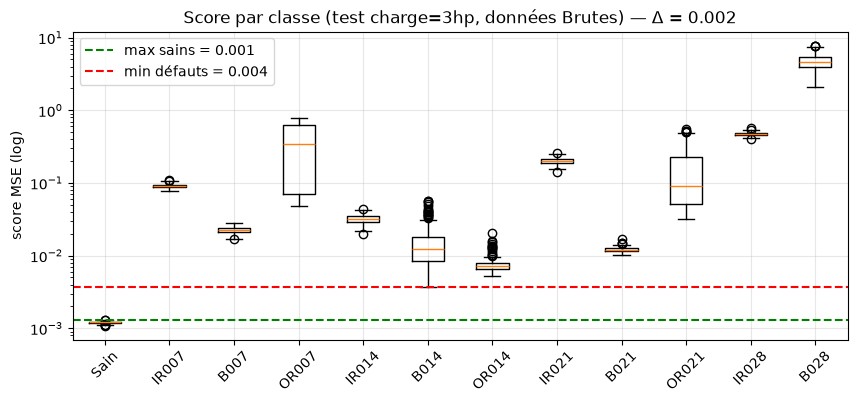

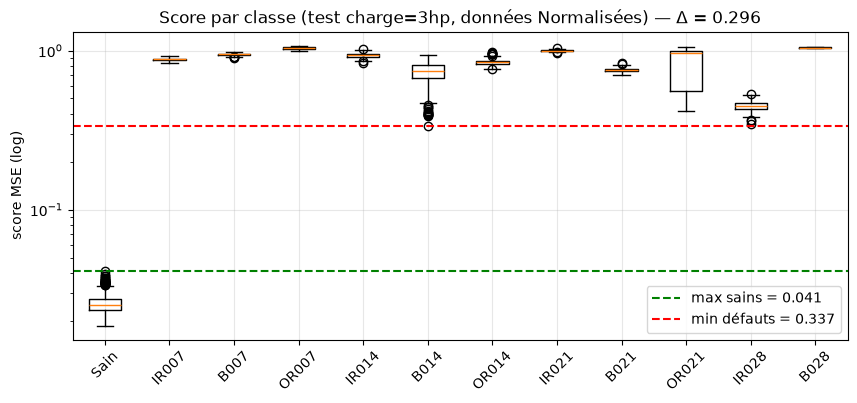

,seuil,AUC,FPR,FNR
variante,,,,
Normalisé,0.0344,1.0,0.0272,0.0
Brut,0.0011,1.0,0.9839,0.0


In [6]:
diam = infos.groupby("classe")["diametre_mils"].first()          # diamètre associé à chaque classe
classes = sorted(infos["classe"].unique(), key=lambda c: (c != "Sain", diam[c]))  # Sain d'abord, puis 7 < 14 < 21

for variante, col in [("Brut", "score_Brut"), ("Normalisé", "score_Normalisé")]:
    s = infos[col].to_numpy()[i_test]
    est_def = infos["defaut_sain"].to_numpy()[i_test] == "Défaut"
    max_sain, min_def = s[~est_def].max(), s[est_def].min()
    delta = min_def - max_sain

    data = [s[infos["classe"].to_numpy()[i_test] == c] for c in classes]
    plt.figure(figsize=(10, 4))
    plt.boxplot(data, tick_labels=classes)
    plt.yscale("log")
    plt.axhline(max_sain, color="green", ls="--", label=f"max sains = {max_sain:.3f}")
    plt.axhline(min_def,  color="red",   ls="--", label=f"min défauts = {min_def:.3f}")
    plt.ylabel("score MSE (log)")
    plt.title(f"Score par classe (test charge=3hp, données {variante}es) — Δ = {delta:.3f}")
    plt.xticks(rotation=45); plt.grid(alpha=0.3); plt.legend(); plt.show()

display(pd.DataFrame(resultats).set_index("variante"))     # ← comparatif final Norm vs Brut

,SNR (dB),AUC,FPR,FNR
0,15,1.0,1.0,0.0
1,10,1.0,1.0,0.0
2,5,1.0,1.0,0.0
3,0,1.0,1.0,0.0


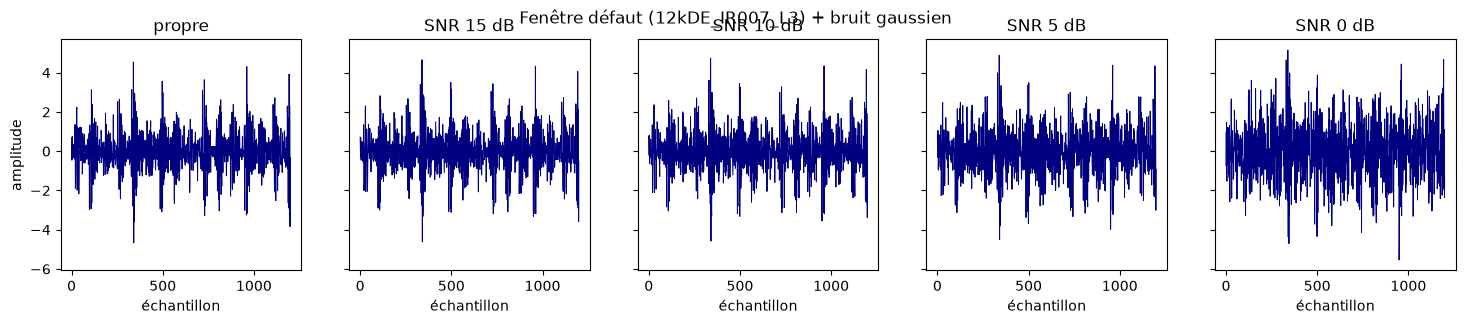

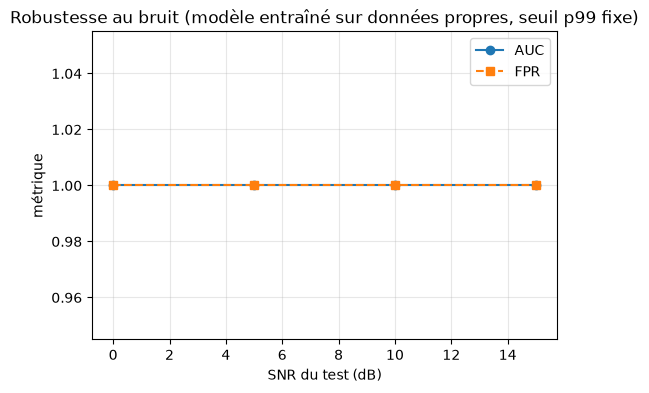

In [7]:
# === Test de robustesse au bruit : on bruite le TEST à différents SNR ===
def ajouter_bruit(x, snr_db, seed=42):
    """Ajoute un bruit gaussien pour obtenir le SNR donné (dB)."""
    rng = np.random.default_rng(seed)
    p_sig = np.mean(x ** 2)                                   # puissance du signal
    p_bruit = p_sig / 10 ** (snr_db / 10)                      # puissance du bruit visée
    return x + np.sqrt(p_bruit) * rng.standard_normal(x.shape)

modele = modeles["Normalisé"]
X_test = SBNorm[i_test]                                       # test normalisé (propre)
y_test = (infos["defaut_sain"].to_numpy()[i_test] == "Défaut").astype(int)
seuil = seuils["Normalisé"]                                   # seuil p99 du train PROPRE (inchangé)

lignes = []
for snr in [15, 10, 5, 0]:
    X_bruit = ajouter_bruit(X_test, snr)
    score_b = score_mse(modele, X_bruit)                      # modèle entraîné sur données propres
    auc = roc_auc_score(y_test, score_b)
    TN, FP, FN, TP = confusion_matrix(y_test, score_b > seuil, labels=[0, 1]).ravel()
    lignes.append({"SNR (dB)": snr, "AUC": round(auc, 3),
                   "FPR": round(FP/(FP+TN), 4), "FNR": round(FN/(FN+TP), 4)})
df_bruit = pd.DataFrame(lignes)
display(df_bruit)


#| label: fig-bruit
#| fig-cap: "Même fenêtre défaut à différents SNR (bruit gaussien ajouté) : propre, 15, 10, 5, 0 dB."
i_def = i_test[~sain[i_test]][0]                 # une fenêtre défaut du test
x = SBNorm[i_def]

niveaux = [None, 15, 10, 5, 0]                    # None = signal propre
titres  = ["propre", "SNR 15 dB", "SNR 10 dB", "SNR 5 dB", "SNR 0 dB"]

fig, axes = plt.subplots(1, 5, figsize=(18, 3), sharex=True, sharey=True)   # mêmes échelles
for ax, snr, titre in zip(axes, niveaux, titres):
    xb = x if snr is None else ajouter_bruit(x, snr, seed=42)   # même bruit reproductible
    ax.plot(xb, color="navy", lw=0.7)
    ax.set_title(titre); ax.set_xlabel("échantillon")
axes[0].set_ylabel("amplitude")
fig.suptitle(f"Fenêtre défaut ({infos.loc[i_def, 'fichier']}) + bruit gaussien")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(df_bruit["SNR (dB)"][::-1], df_bruit["AUC"], "o-", label="AUC")
plt.plot(df_bruit["SNR (dB)"][::-1], df_bruit["FPR"], "s--", label="FPR")
plt.xlabel("SNR du test (dB)"); plt.ylabel("métrique")
plt.title("Robustesse au bruit (modèle entraîné sur données propres, seuil p99 fixe)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

#### **Données brutes** : 
1. Les deux distributions sont proche : l'amplitude absolue du signal (qui dépend de la charge), brouille la détection, même si elle fonctionne ici (sains séparés des défauts)
2. La séparation ayant une marge faible (cf graph Δ) entre les sains et les défauts, la détection d'anomalie est beacoup moins précise, et le seuil sépare mal les sains et défauts : **Taux de faux positif (FPR) = 99%**.

#### **Données normalisées** : 
1. Les défauts ont des scores nettement mieux séparés entre sains et défaut : l'amplitude est "normalisée", son influence est donc réduite.
2. La séparation ayant une marge plus grande (cf graph Δ) entre les sains et les défauts, la détection d'anomalie est nette, et le seuil sépare correctement les sains et défauts : **Taux de faux positif (FPR) = 2%**.

## **Conclusion :**
- La charge a une influence pour ce type de modèle. Il sera donc important de l'entrainer sur des données saines sous différentes charges pour avoir une bonne détection.
- La normalisation des données permet de gommer l'effet charge, ce qui était un des aspects que nous voulions vérifier.
- Aucun faux négatif : impératif pour de la détection d'anomalie : mieux vaut trop d'alertes qu'un casse.
- Avec les données normalisées, le modèles identifie bien les défauts, même avec une faible sévérité.


### **Limites :**

Les données testées sont dans des conditions optimales : pas de bruit, défaut clairement marqué (même à faible sévérité), etc...
En situation réelle, les conditions seront beaucoup plus difficiles, les résultats seront probablement moins bon.

### **Suites possibles :**

- Tester sur des données issues du milieu industriel
- Améliorer l'étape de traitement de signal dans le préprocessing pour filtrer les parasites et le bruit
- Améliorer la définition des paramètres notamment :
    - Le seuil d'identification : joue sur le ratio **nombre alerte vs risque**
    - La taille des fenêtres et le callback: joue sur le ratio **performance vs coût (de calcul)**